# 01 · EDA: phân bố, giá trị thiếu, rút lui theo ngày

In [12]:
import os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

SEED = 42
np.random.seed(SEED)
CUTOFF_DAY = 28                # tham số; khớp config.cutoff_day của Trường

CWD = Path.cwd().resolve()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RAW_DIR = Path(os.environ.get("OULAD_RAW_DIR", ROOT / "data" / "raw"))
RESULTS_DIR = Path(os.environ.get("OULAD_RESULTS_DIR", ROOT / "results"))
EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from src.etl.features_demographic import EDUCATION_ORDER, AGE_ORDER, KEYS, _imd_to_ordinal

# ---- kiểu dáng: nền sáng, mực trung tính, lưới mờ, mark mảnh; màu theo bảng đã kiểm định ----
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898883", "#e4e3de"
BLUE, ORANGE, BLUE_LIGHT, GREY = "#2a78d6", "#eb6834", "#9ec5f4", "#b8b7b0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
FMT_INT = FuncFormatter(lambda x, _: f"{x:,.0f}")

MANIFEST = []
def finish(fig, cid, slug, title, source, n, window, label_used, data):
    # ghi n, nguồn, cửa sổ lên hình; lưu PNG + CSV; ghi vào manifest
    note = "chỉ mô tả toàn bộ dữ liệu, không dùng chọn feature" if label_used else "không dùng nhãn"
    fig.text(0.01, 0.006, f"n = {n:,} · nguồn: {source} · cửa sổ: {window} · {note}",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    png, csv = EDA_DIR / f"{cid}_{slug}.png", EDA_DIR / f"{cid}_{slug}.csv"
    fig.savefig(png, dpi=150)
    data.to_csv(csv, index=False, encoding="utf-8-sig")
    MANIFEST.append(dict(chart_id=cid, title=title, source=source, n=int(n), window=window,
                         label_used="có (mô tả, toàn bộ)" if label_used else "không",
                         png=png.name, csv=csv.name))
    plt.show()

## 1. Đọc dữ liệu cần dùng

In [13]:
NA = ["?", ""]
need = ["studentInfo", "studentRegistration", "studentVle"]
missing_files = [t for t in need if not (RAW_DIR / f"{t}.csv").exists()]
if missing_files:
    raise FileNotFoundError(f"Thiếu file trong {RAW_DIR}: {[t + '.csv' for t in missing_files]}")

student_info = pd.read_csv(RAW_DIR / "studentInfo.csv", na_values=NA, dtype={"id_student": "int32"})
student_reg = pd.read_csv(RAW_DIR / "studentRegistration.csv", na_values=NA, dtype={"id_student": "int32"})
# studentVle: chỉ đọc 2 cột cần cho biểu đồ theo ngày, ép kiểu nhỏ để nhẹ RAM
svle = pd.read_csv(RAW_DIR / "studentVle.csv", usecols=["date", "sum_click"], na_values=NA,
                   dtype={"date": "int16", "sum_click": "int32"})

N_ALL = len(student_reg)
print(f"studentInfo={len(student_info):,} | studentRegistration={N_ALL:,} | studentVle={len(svle):,} dòng")
assert len(student_info) == N_ALL, "studentInfo và studentRegistration lệch số dòng; xem báo cáo chất lượng"
assert not student_reg.duplicated(KEYS).any() and not student_info.duplicated(KEYS).any()
SUMMARY = {}   # gom số liệu chính để ghi tóm tắt cuối notebook

studentInfo=32,593 | studentRegistration=32,593 | studentVle=10,655,280 dòng


## 2. w2_01 · Phân bố `final_result`

Toàn bộ 32.593 lượt đăng ký, theo đúng bảng biểu đồ của kế hoạch. Chỉ để hiểu nhãn, **không** dùng để chọn feature. Lớp dương của `label_withdrawn` là Withdrawn; nhớ rằng mô hình chỉ dự đoán cho người còn học ở ngày 28.

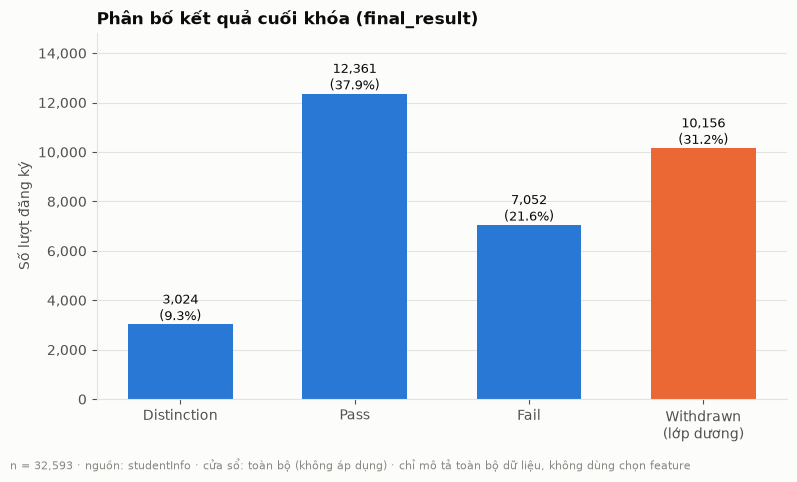

có date_unregistration,False,True
final_result == Withdrawn,,
False,22428,9
True,93,10063


Withdrawn nhưng trống date_unregistration: 93 | có date_unregistration nhưng không Withdrawn: 9


In [14]:
order = ["Distinction", "Pass", "Fail", "Withdrawn"]
vc = student_info["final_result"].value_counts()
order += [k for k in vc.index if k not in order]          # giá trị lạ (nếu có) vẫn được vẽ
fr = vc.reindex(order).fillna(0).astype(int)
n1 = int(fr.sum())

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(range(len(fr)), fr.values, width=0.6, color=[ORANGE if k == "Withdrawn" else BLUE for k in fr.index])
for i, v in enumerate(fr.values):
    ax.text(i, v, f"{v:,}\n({v / n1:.1%})", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(range(len(fr)))
ax.set_xticklabels([k + ("\n(lớp dương)" if k == "Withdrawn" else "") for k in fr.index])
ax.set_ylim(0, fr.max() * 1.2)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_ylabel("Số lượt đăng ký")
ax.grid(axis="x", visible=False)
ax.set_title("Phân bố kết quả cuối khóa (final_result)")

d1 = pd.DataFrame({"final_result": fr.index, "n": fr.values, "pct": (fr.values / n1).round(4)})
finish(fig, "w2_01", "final_result", "Phân bố final_result", "studentInfo", n1, "toàn bộ (không áp dụng)", True, d1)
SUMMARY["w2_01"] = {k: int(v) for k, v in fr.items()}

# Kiểm tra nhất quán: Withdrawn có khớp với việc có date_unregistration không? (toàn bộ dữ liệu, chỉ để báo Trường)
chk = student_info[KEYS + ["final_result"]].merge(
    student_reg[KEYS + ["date_unregistration"]], on=KEYS, how="left", validate="one_to_one")
ct = pd.crosstab(chk["final_result"].eq("Withdrawn"), chk["date_unregistration"].notna(),
                 rownames=["final_result == Withdrawn"], colnames=["có date_unregistration"])
display(ct)
SUMMARY["wd_without_unreg"] = int(ct.loc[True, False]) if (True in ct.index and False in ct.columns) else 0
SUMMARY["unreg_not_wd"] = int(ct.loc[False, True]) if (False in ct.index and True in ct.columns) else 0
print("Withdrawn nhưng trống date_unregistration:", SUMMARY["wd_without_unreg"],
      "| có date_unregistration nhưng không Withdrawn:", SUMMARY["unreg_not_wd"])

## 3. w2_02 · Số lượt đăng ký rút lui tích lũy theo ngày

Dùng toàn bộ 32.593 lượt đăng ký (checklist: phải ghi rõ). Biểu đồ giải thích vì sao chọn cửa sổ 28 ngày và vì sao cohort bị loại bớt người rút sớm. Cohort = còn đăng ký ở đầu ngày 28 (`date_unregistration` trống hoặc ≥ 28).

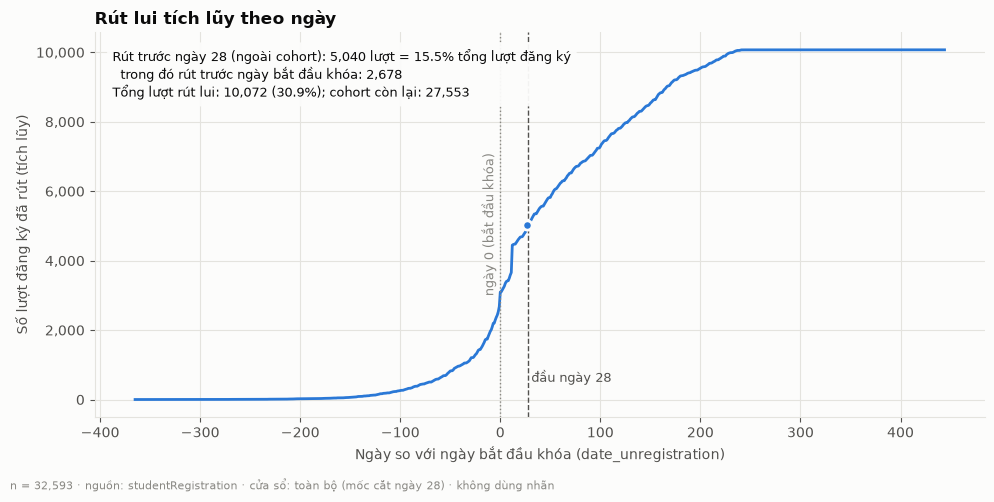

In [15]:
du = student_reg["date_unregistration"].dropna().astype(int)
by_day = du.value_counts().sort_index()
days = np.arange(by_day.index.min(), by_day.index.max() + 1)
daily = by_day.reindex(days, fill_value=0)
cum = daily.cumsum()

n_wd = int(len(du))
n_early = int((du < CUTOFF_DAY).sum())        # rút trước ngày 28 -> ngoài cohort
n_neg = int((du < 0).sum())                   # rút trước ngày bắt đầu khóa
n_cohort = N_ALL - n_early
cum_at_cut = int(cum.loc[CUTOFF_DAY - 1])     # số đã rút tính đến hết ngày 27
assert cum_at_cut == n_early

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(days, cum.values, color=BLUE, lw=2)
ax.axvline(CUTOFF_DAY, color=INK2, lw=1, ls="--")
ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.scatter([CUTOFF_DAY - 1], [cum_at_cut], s=45, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=5)
ax.text(CUTOFF_DAY + 3, ax.get_ylim()[1] * 0.04, f"đầu ngày {CUTOFF_DAY}", color=INK2, fontsize=9, va="bottom")
ax.text(-4, 0.5, "ngày 0 (bắt đầu khóa)", color=MUTED, fontsize=9, va="center", ha="right",
        rotation=90, transform=ax.get_xaxis_transform())
ax.text(0.02, 0.96,
        f"Rút trước ngày {CUTOFF_DAY} (ngoài cohort): {n_early:,} lượt = {n_early / N_ALL:.1%} tổng lượt đăng ký\n"
        f"  trong đó rút trước ngày bắt đầu khóa: {n_neg:,}\n"
        f"Tổng lượt rút lui: {n_wd:,} ({n_wd / N_ALL:.1%}); cohort còn lại: {n_cohort:,}",
        transform=ax.transAxes, va="top", fontsize=9.5, color=INK, zorder=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_xlabel("Ngày so với ngày bắt đầu khóa (date_unregistration)")
ax.set_ylabel("Số lượt đăng ký đã rút (tích lũy)")
ax.set_title("Rút lui tích lũy theo ngày")

d2 = pd.DataFrame({"day": days, "n_unregistered": daily.values, "cumulative": cum.values,
                   "cumulative_pct_of_all": (cum.values / N_ALL).round(5)})
finish(fig, "w2_02", "withdrawn_cumulative", "Rút lui tích lũy theo ngày", "studentRegistration",
       N_ALL, f"toàn bộ (mốc cắt ngày {CUTOFF_DAY})", False, d2)
SUMMARY["w2_02"] = dict(n_all=N_ALL, n_withdraw_dates=n_wd, n_early=n_early, n_neg=n_neg, n_cohort=n_cohort)

## 3b. w2_02b · Đỉnh rút lui theo ngày: module/đợt nào đóng góp?

Đường tích lũy ở w2_02 có bước nhảy quanh ngày 0 và quanh ngày 12. Biểu đồ này vẽ **số lượt rút mỗi ngày** (không tích lũy) trong khoảng ngày -30 đến 60 và chỉ ra module/đợt nào chiếm phần lớn ở 3 ngày cao nhất. Nếu một module/đợt chiếm gần hết một đỉnh, đó là mốc riêng của khóa đó (ví dụ hạn hủy đăng ký), không phải hành vi chung. Không dùng nhãn.

,day,n_day,module_presentation,n_mp,share_of_day
0,12,788,FFF 2014J,217,0.275
1,12,788,BBB 2014J,181,0.230
2,12,788,CCC 2014J,135,0.171
3,0,419,BBB 2013J,102,0.243
4,0,419,FFF 2013J,79,0.189
5,0,419,DDD 2013J,41,0.098
6,27,170,BBB 2013B,59,0.347
7,27,170,FFF 2013B,47,0.276
8,27,170,DDD 2013B,34,0.200


Trung vị số lượt rút mỗi ngày trong khoảng -30..60: 45


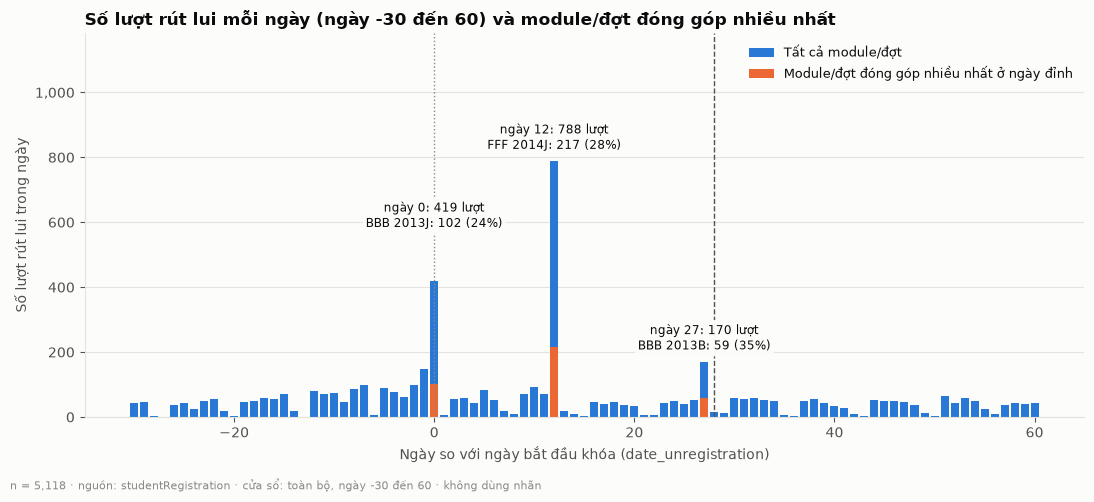

Ngày 12: 788 lượt; lớn nhất FFF 2014J chiếm 28% -> phân tán qua nhiều khóa
Ngày 0: 419 lượt; lớn nhất BBB 2013J chiếm 24% -> phân tán qua nhiều khóa
Ngày 27: 170 lượt; lớn nhất BBB 2013B chiếm 35% -> phân tán qua nhiều khóa


In [16]:
reg_d = student_reg.dropna(subset=["date_unregistration"]).copy()
reg_d["day"] = reg_d["date_unregistration"].astype(int)
reg_d["mp"] = reg_d["code_module"].astype(str) + " " + reg_d["code_presentation"].astype(str)

LO, HI = -30, 60
win = reg_d[(reg_d["day"] >= LO) & (reg_d["day"] <= HI)]
daily_w = win.groupby("day").size().reindex(range(LO, HI + 1), fill_value=0)
top_days = daily_w.sort_values(ascending=False).head(3).index.tolist()

rows_sp = []
for d in top_days:
    vc = win.loc[win["day"] == d, "mp"].value_counts()
    for mp, c in vc.head(3).items():
        rows_sp.append(dict(day=int(d), n_day=int(daily_w[d]), module_presentation=mp,
                            n_mp=int(c), share_of_day=round(c / daily_w[d], 3)))
spikes = pd.DataFrame(rows_sp)
display(spikes)
print(f"Trung vị số lượt rút mỗi ngày trong khoảng {LO}..{HI}: {daily_w.median():.0f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(daily_w.index, daily_w.values, width=0.8, color=BLUE, label="Tất cả module/đợt")
for k, d in enumerate(top_days):
    first = spikes[spikes["day"] == d].iloc[0]
    if k == 0:
        ax.bar([d], [first["n_mp"]], width=0.8, color=ORANGE, label="Module/đợt đóng góp nhiều nhất ở ngày đỉnh")
    else:
        ax.bar([d], [first["n_mp"]], width=0.8, color=ORANGE)
    if daily_w[d] >= 3 * max(daily_w.median(), 1):          # chỉ gắn nhãn đỉnh vượt rõ mức thường ngày
        ax.annotate(f"ngày {d}: {first['n_day']:,} lượt\n{first['module_presentation']}: {first['n_mp']:,} ({first['share_of_day']:.0%})",
                    (d, daily_w[d]), xytext=(0, 6 + 30 * (k % 2)), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, color=INK, zorder=10,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.axvline(CUTOFF_DAY, color=INK2, lw=1, ls="--")
ax.set_ylim(0, daily_w.max() * 1.5)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_xlabel("Ngày so với ngày bắt đầu khóa (date_unregistration)")
ax.set_ylabel("Số lượt rút lui trong ngày")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"Số lượt rút lui mỗi ngày (ngày {LO} đến {HI}) và module/đợt đóng góp nhiều nhất")

top_by_day = (win.groupby(["day", "mp"]).size().rename("n_top").reset_index()
                 .sort_values(["day", "n_top"], ascending=[True, False]).drop_duplicates("day")
                 .rename(columns={"mp": "top_module_presentation"}))
d2b = daily_w.rename("n_unregistered").reset_index().merge(top_by_day, on="day", how="left")
finish(fig, "w2_02b", "withdrawn_spikes", "Đỉnh rút lui theo ngày và module/đợt đóng góp", "studentRegistration",
       len(win), f"toàn bộ, ngày {LO} đến {HI}", False, d2b)
SUMMARY["w2_02b"] = [dict(day=int(d), n_day=int(daily_w[d]),
                          mp=spikes[spikes["day"] == d].iloc[0]["module_presentation"],
                          share=float(spikes[spikes["day"] == d].iloc[0]["share_of_day"])) for d in top_days]
for r in SUMMARY["w2_02b"]:
    kind = "mốc riêng của một khóa" if r["share"] >= 0.5 else "phân tán qua nhiều khóa"
    print(f"Ngày {r['day']}: {r['n_day']:,} lượt; lớn nhất {r['mp']} chiếm {r['share']:.0%} -> {kind}")

## 4. w2_03 · Cỡ lượt đăng ký và cohort theo module/đợt

Chỉ cỡ, không có nhãn. Phần tỉ lệ nhãn theo module (biểu đồ 3 đầy đủ) làm ở tuần 3 trên cohort, sau khi Trường giao bảng.

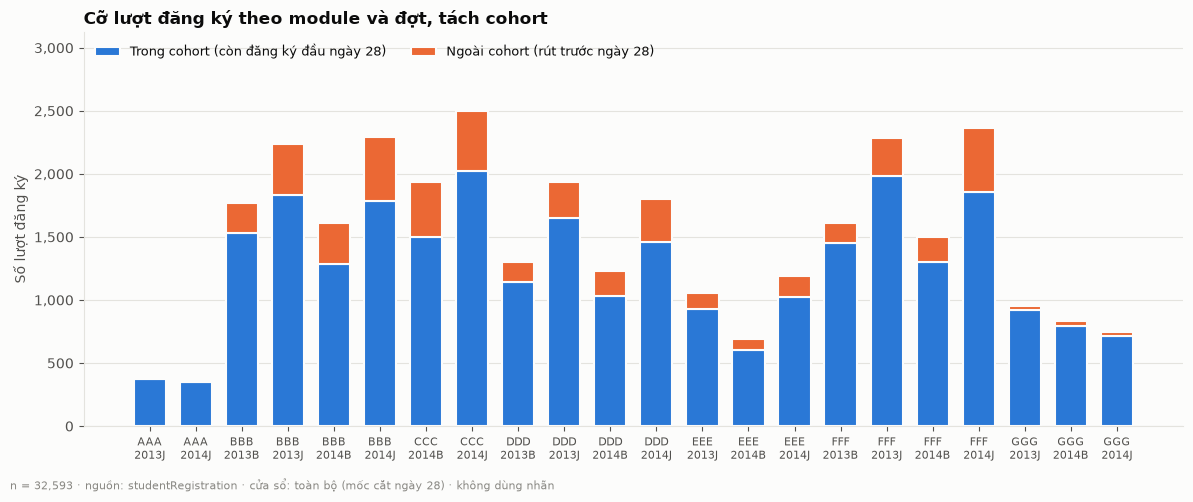

,code_module,code_presentation,in_cohort,registered,excluded_early,pct_excluded
6,CCC,2014B,1500,1936,436,0.2252
5,BBB,2014J,1787,2292,505,0.2203
18,FFF,2014J,1860,2365,505,0.2135
4,BBB,2014B,1282,1613,331,0.2052
7,CCC,2014J,2023,2498,475,0.1902


In [17]:
reg = student_reg.assign(in_cohort=~(student_reg["date_unregistration"] < CUTOFF_DAY))
g = (reg.groupby(["code_module", "code_presentation"])["in_cohort"]
        .agg(in_cohort="sum", registered="size").reset_index())
g["excluded_early"] = g["registered"] - g["in_cohort"]
g["pct_excluded"] = (g["excluded_early"] / g["registered"]).round(4)
g["label"] = g["code_module"] + "\n" + g["code_presentation"]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(g))
ax.bar(x, g["in_cohort"], width=0.7, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label="Trong cohort (còn đăng ký đầu ngày 28)")
ax.bar(x, g["excluded_early"], bottom=g["in_cohort"], width=0.7, color=ORANGE, edgecolor=SURFACE,
       linewidth=1.5, label="Ngoài cohort (rút trước ngày 28)")
ax.set_xticks(x); ax.set_xticklabels(g["label"], fontsize=8)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_ylabel("Số lượt đăng ký")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, g["registered"].max() * 1.25)          # chừa chỗ cho chú thích, không đè lên cột
ax.legend(loc="upper left", fontsize=9, ncol=2)
ax.set_title("Cỡ lượt đăng ký theo module và đợt, tách cohort")

finish(fig, "w2_03", "cohort_size_by_module", "Cỡ lượt đăng ký và cohort theo module/đợt",
       "studentRegistration", N_ALL, f"toàn bộ (mốc cắt ngày {CUTOFF_DAY})", False,
       g.drop(columns="label"))
display(g.drop(columns="label").sort_values("pct_excluded", ascending=False).head(5))
SUMMARY["w2_03"] = dict(max_excl_pct=float(g["pct_excluded"].max()),
                        max_excl_where=g.loc[g["pct_excluded"].idxmax(), "label"].replace("\n", " "),
                        min_excl_pct=float(g["pct_excluded"].min()),
                        smallest_n=int(g["registered"].min()))

## 5. w2_04 · Giá trị thiếu theo cột

Chỉ vẽ cột có thiếu. Lưu ý `date_unregistration` trống nghĩa là **không rút lui**, không phải lỗi dữ liệu.

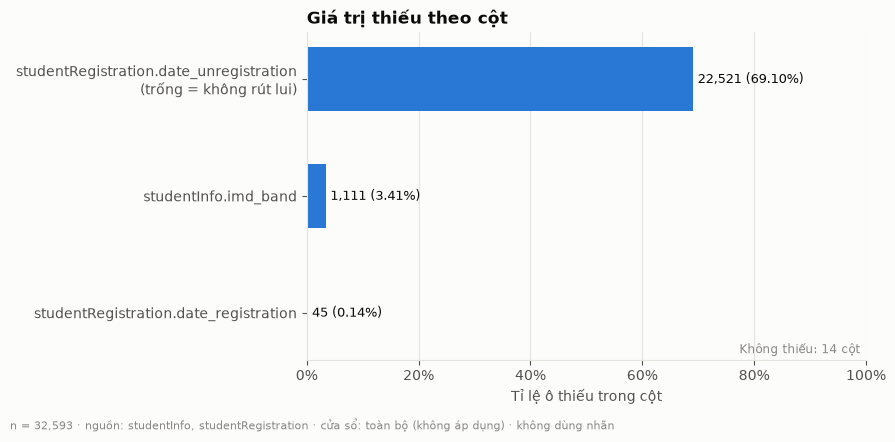

In [18]:
rows = []
for tname, d in (("studentInfo", student_info), ("studentRegistration", student_reg)):
    for c in d.columns:
        n_na = int(d[c].isna().sum())
        rows.append(dict(table=tname, column=c, n_missing=n_na, pct_missing=n_na / len(d), n_rows=len(d)))
miss = pd.DataFrame(rows)
shown = miss[miss["n_missing"] > 0].sort_values("pct_missing")
n4 = len(student_info)

fig, ax = plt.subplots(figsize=(9, 2.6 + 0.6 * len(shown)))
ylabels = [f"{r.table}.{r.column}" + ("\n(trống = không rút lui)" if r.column == "date_unregistration" else "")
           for r in shown.itertuples()]
ax.barh(range(len(shown)), shown["pct_missing"] * 100, height=0.55, color=BLUE)
for i, r in enumerate(shown.itertuples()):
    ax.text(r.pct_missing * 100 + 0.8, i, f"{r.n_missing:,} ({r.pct_missing:.2%})", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(shown))); ax.set_yticklabels(ylabels)
ax.set_xlim(0, max(100, shown["pct_missing"].max() * 100 * 1.3) if len(shown) else 100)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlabel("Tỉ lệ ô thiếu trong cột")
ax.grid(axis="y", visible=False)
ax.set_title("Giá trị thiếu theo cột")
no_missing = miss.loc[miss["n_missing"] == 0, "column"].tolist()
ax.text(0.99, 0.02, f"Không thiếu: {len(no_missing)} cột", transform=ax.transAxes, ha="right", fontsize=8.5, color=MUTED)

finish(fig, "w2_04", "missing_by_column", "Giá trị thiếu theo cột", "studentInfo, studentRegistration",
       n4, "toàn bộ (không áp dụng)", False, miss)
SUMMARY["w2_04"] = {f"{r.table}.{r.column}": int(r.n_missing) for r in shown.itertuples()}

## 6. w2_05 · Phân bố nhân khẩu học (không nhãn)

Mô tả cơ cấu sinh viên. Mã hóa thứ tự dùng đúng quy ước của `features_demographic.py` (học vấn 0–4, `imd_band` 0–9, tuổi 0–2). Vai trò dự báo của các cột này (so với tỉ lệ rút lui) làm ở tuần 3 trên train.

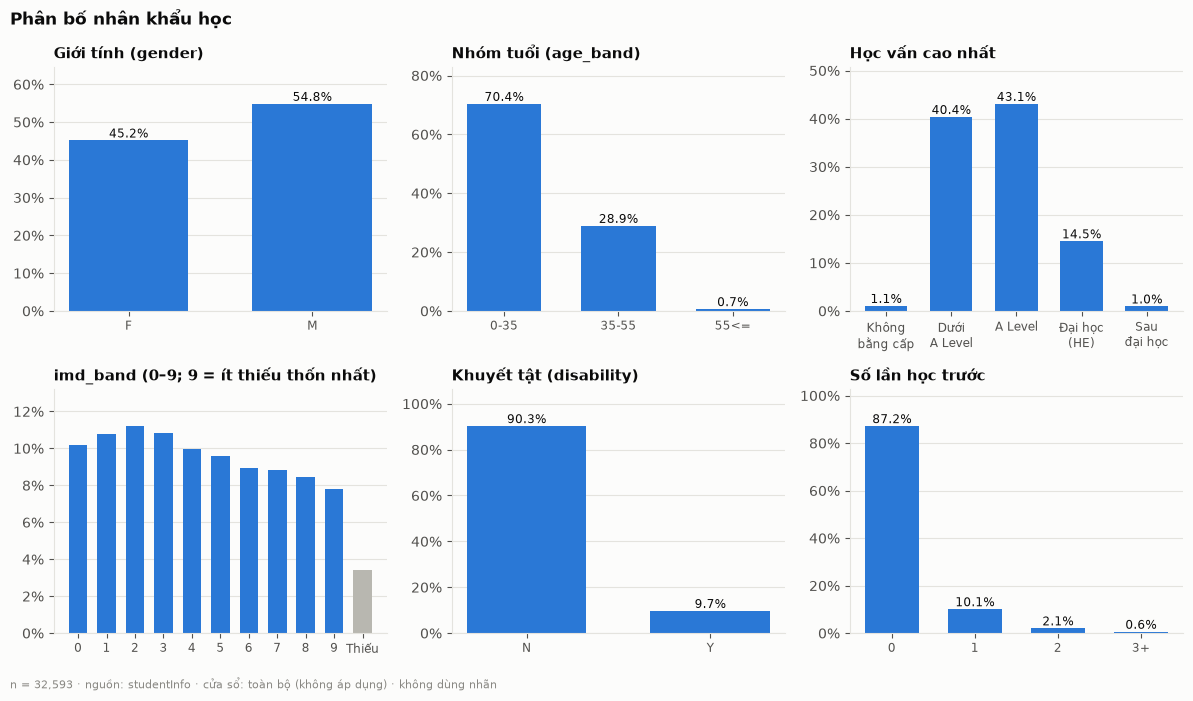

In [19]:
EDU_LABEL = {"No Formal quals": "Không\nbằng cấp", "Lower Than A Level": "Dưới\nA Level",
             "A Level or Equivalent": "A Level", "HE Qualification": "Đại học\n(HE)",
             "Post Graduate Qualification": "Sau\nđại học"}
n5 = len(student_info)

def counts(series, order):
    s = series.astype("string").str.strip()
    c = s.value_counts().reindex(order).fillna(0).astype(int)
    return c

panels = []
panels.append(("Giới tính (gender)", counts(student_info["gender"], ["F", "M"]), ["F", "M"]))
panels.append(("Nhóm tuổi (age_band)", counts(student_info["age_band"], list(AGE_ORDER)), list(AGE_ORDER)))
edu = counts(student_info["highest_education"], list(EDUCATION_ORDER))
panels.append(("Học vấn cao nhất", edu, [EDU_LABEL.get(k, k) for k in edu.index]))
imd = _imd_to_ordinal(student_info["imd_band"])
imd_c = imd.value_counts().sort_index()
imd_c.index = [str(int(i)) for i in imd_c.index]
imd_c["Thiếu"] = int(imd.isna().sum())
panels.append(("imd_band (0–9; 9 = ít thiếu thốn nhất)", imd_c, list(imd_c.index)))
panels.append(("Khuyết tật (disability)", counts(student_info["disability"], ["N", "Y"]), ["N", "Y"]))
prev = student_info["num_of_prev_attempts"].clip(upper=3)
prev_c = prev.value_counts().sort_index()
panels.append(("Số lần học trước", prev_c, ["0", "1", "2", "3+"][:len(prev_c)]))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
rows5 = []
for ax, (title, c, labels) in zip(axes.ravel(), panels):
    pct = c.values / n5 * 100
    colors = [GREY if l == "Thiếu" else BLUE for l in labels]
    ax.bar(range(len(c)), pct, width=0.65, color=colors)
    if len(c) <= 6:
        for i, p in enumerate(pct):
            ax.text(i, p, f"{p:.1f}%", ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_xticks(range(len(c))); ax.set_xticklabels(labels, fontsize=8.5)
    ax.set_ylim(0, max(pct) * 1.18)
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title, fontsize=10.5)
    for lab, cnt in zip(labels, c.values):
        rows5.append(dict(variable=title, category=str(lab).replace("\n", " "), n=int(cnt), pct=round(cnt / n5, 4)))
fig.suptitle("Phân bố nhân khẩu học", x=0.01, ha="left", fontsize=12, fontweight="bold")
d5 = pd.DataFrame(rows5)
finish(fig, "w2_05", "demographics", "Phân bố nhân khẩu học", "studentInfo", n5, "toàn bộ (không áp dụng)", False, d5)
SUMMARY["w2_05"] = dict(female_pct=float(counts(student_info["gender"], ["F", "M"])["F"] / n5),
                        age_55_pct=float(counts(student_info["age_band"], list(AGE_ORDER)).iloc[-1] / n5),
                        disability_pct=float(counts(student_info["disability"], ["N", "Y"])["Y"] / n5))

## 7. w2_06 · Phân bố `date_registration`

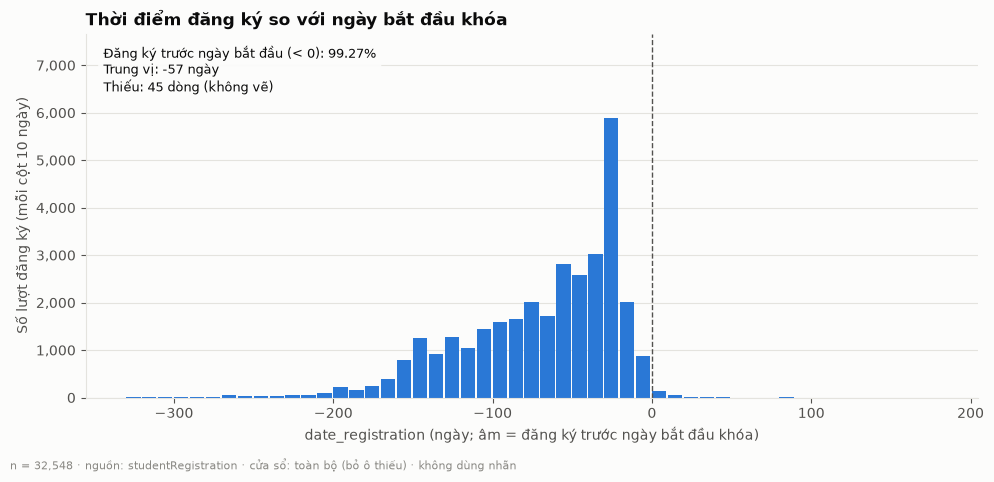

In [20]:
dr = student_reg["date_registration"].dropna()
n6 = len(dr)
lo, hi = int(np.floor(dr.min() / 10) * 10), int(np.ceil(dr.max() / 10) * 10) + 10
edges = np.arange(lo, hi + 1, 10)
hist, _ = np.histogram(dr, bins=edges)
share_before = float((dr < 0).mean())

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(edges[:-1], hist, width=9, align="edge", color=BLUE)
ax.axvline(0, color=INK2, lw=1, ls="--")
ax.set_ylim(0, hist.max() * 1.3)                  # chừa khoảng trống phía trên cho chú thích
ax.text(0.02, 0.97,
        f"Đăng ký trước ngày bắt đầu (< 0): {share_before:.2%}\nTrung vị: {dr.median():.0f} ngày\n"
        f"Thiếu: {int(student_reg['date_registration'].isna().sum()):,} dòng (không vẽ)",
        transform=ax.transAxes, ha="left", va="top", fontsize=9.5, zorder=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_xlabel("date_registration (ngày; âm = đăng ký trước ngày bắt đầu khóa)")
ax.set_ylabel("Số lượt đăng ký (mỗi cột 10 ngày)")
ax.grid(axis="x", visible=False)
ax.set_title("Thời điểm đăng ký so với ngày bắt đầu khóa")

d6 = pd.DataFrame({"bin_left": edges[:-1], "bin_right": edges[1:], "n": hist})
finish(fig, "w2_06", "date_registration", "Phân bố date_registration", "studentRegistration", n6,
       "toàn bộ (bỏ ô thiếu)", False, d6)
SUMMARY["w2_06"] = dict(n=n6, share_before=share_before, median=float(dr.median()))

## 8. w2_07 · Tổng click VLE theo ngày

Toàn bộ `studentVle` trên **mọi ngày** (không lọc), để thấy hành vi giảm dần và phần nằm trong cửa sổ 0–27. Đây không phải biểu đồ hành vi 28 ngày; ngày từ 28 trở đi chỉ xuất hiện ở đây để minh họa, không dùng làm feature.

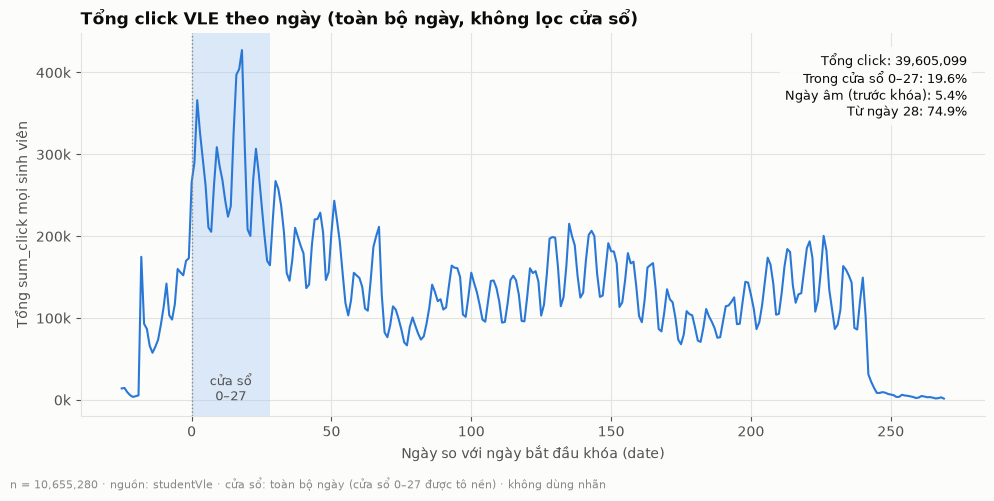

In [21]:
day = svle.groupby("date")["sum_click"].agg(total_clicks="sum", n_rows="size")
day.index = day.index.astype(int)
total = int(day["total_clicks"].sum())
in_win = int(day.loc[(day.index >= 0) & (day.index < CUTOFF_DAY), "total_clicks"].sum())
neg = int(day.loc[day.index < 0, "total_clicks"].sum())
late = total - in_win - neg

fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(0, CUTOFF_DAY, color=BLUE_LIGHT, alpha=0.35, linewidth=0)
ax.plot(day.index, day["total_clicks"].values, color=BLUE, lw=1.5)
ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.text(CUTOFF_DAY / 2, 0.03, "cửa sổ\n0–27", ha="center", va="bottom", fontsize=9, color=INK2,
        transform=ax.get_xaxis_transform())
ax.text(0.98, 0.95,
        f"Tổng click: {total:,}\nTrong cửa sổ 0–{CUTOFF_DAY - 1}: {in_win / total:.1%}\n"
        f"Ngày âm (trước khóa): {neg / total:.1%}\nTừ ngày {CUTOFF_DAY}: {late / total:.1%}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9.5, zorder=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k") if day["total_clicks"].max() >= 20000 else FMT_INT)
ax.set_xlabel("Ngày so với ngày bắt đầu khóa (date)")
ax.set_ylabel("Tổng sum_click mọi sinh viên")
ax.set_title("Tổng click VLE theo ngày (toàn bộ ngày, không lọc cửa sổ)")

d7 = day.reset_index().rename(columns={"date": "day"})
finish(fig, "w2_07", "vle_clicks_by_day", "Tổng click VLE theo ngày", "studentVle", len(svle),
       "toàn bộ ngày (cửa sổ 0–27 được tô nền)", False, d7)
SUMMARY["w2_07"] = dict(total=total, in_win_pct=in_win / total, neg_pct=neg / total, late_pct=late / total,
                        peak_day=int(day["total_clicks"].idxmax()))

## 9. Manifest và tóm tắt số liệu

`eda_manifest.csv` liệt kê mỗi hình kèm n, nguồn, cửa sổ, có dùng nhãn hay không. `eda_week2_summary.md` gom các con số chính để đối chiếu với bảng feature của Trường.

In [22]:
manifest = pd.DataFrame(MANIFEST)
manifest.to_csv(EDA_DIR / "eda_manifest.csv", index=False, encoding="utf-8-sig")
display(manifest)

S = SUMMARY
w1 = S["w2_01"]; w2 = S["w2_02"]; w3 = S["w2_03"]; w5 = S["w2_05"]; w6 = S["w2_06"]; w7 = S["w2_07"]
def pct(x, n=N_ALL): return f"{x / n:.2%}"

lines = [
    "# Tóm tắt EDA tuần 2 (Đạt)", "",
    f"cutoff_day = {CUTOFF_DAY}. Số liệu đều từ toàn bộ dữ liệu thô; không có biểu đồ nào dùng nhãn để chọn feature.", "",
    "## Số liệu chính để đối chiếu với Trường (mục D)", "",
    f"- Tổng lượt đăng ký: **{w2['n_all']:,}**.",
    f"- Rút trước ngày {CUTOFF_DAY} (ngoài cohort): **{w2['n_early']:,}** ({pct(w2['n_early'])}), trong đó rút trước ngày bắt đầu khóa: {w2['n_neg']:,}.",
    f"- Cohort (còn đăng ký đầu ngày {CUTOFF_DAY}): **{w2['n_cohort']:,}**.",
    "- final_result (toàn bộ): " + "; ".join(f"{k} {v:,} ({pct(v)})" for k, v in w1.items()) + ".",
    f"- Withdrawn nhưng trống date_unregistration: **{S['wd_without_unreg']:,}**; có date_unregistration nhưng không Withdrawn: **{S['unreg_not_wd']:,}**. "
    "Nếu khác 0, báo Trường vì ảnh hưởng cách xác định cohort và nhãn.",
    f"- Tỉ lệ rút sớm theo module/đợt dao động {w3['min_excl_pct']:.1%} đến {w3['max_excl_pct']:.1%} (cao nhất: {w3['max_excl_where']}); đợt nhỏ nhất có {w3['smallest_n']:,} lượt đăng ký.",
    f"- date_registration: {w6['share_before']:.2%} đăng ký trước ngày bắt đầu; trung vị {w6['median']:.0f} ngày.",
    f"- Click VLE (tỉ lệ theo tổng số click, không phải số dòng): {w7['in_win_pct']:.1%} nằm trong cửa sổ 0–{CUTOFF_DAY - 1}, {w7['neg_pct']:.1%} ở ngày âm, {w7['late_pct']:.1%} từ ngày {CUTOFF_DAY}; ngày đông nhất: ngày {w7['peak_day']}.", "",
    "## Danh sách hình", "",
]
if "w2_02b" in S:
    idx = lines.index("## Danh sách hình")
    lines.insert(idx - 1, "- Đỉnh rút lui (ngày -30..60): " + "; ".join(
        f"ngày {r['day']} = {r['n_day']:,} lượt, lớn nhất {r['mp']} ({r['share']:.0%})" for r in S["w2_02b"]) + ".")
lines += [f"- `{r.png}` (n = {r.n:,}, nguồn: {r.source}, nhãn: {r.label_used})" for r in manifest.itertuples()]
(EDA_DIR / "eda_week2_summary.md").write_text("\n".join(lines), encoding="utf-8")

,chart_id,title,source,n,window,label_used,png,csv
0,w2_01,Phân bố final_result,studentInfo,32593,toàn bộ (không áp dụng),"có (mô tả, toàn bộ)",w2_01_final_result.png,w2_01_final_result.csv
1,w2_02,Rút lui tích lũy theo ngày,studentRegistration,32593,toàn bộ (mốc cắt ngày 28),không,w2_02_withdrawn_cumulative.png,w2_02_withdrawn_cumulative.csv
2,w2_02b,Đỉnh rút lui theo ngày và module/đợt đóng góp,studentRegistration,5118,"toàn bộ, ngày -30 đến 60",không,w2_02b_withdrawn_spikes.png,w2_02b_withdrawn_spikes.csv
3,w2_03,Cỡ lượt đăng ký và cohort theo module/đợt,studentRegistration,32593,toàn bộ (mốc cắt ngày 28),không,w2_03_cohort_size_by_module.png,w2_03_cohort_size_by_module.csv
4,w2_04,Giá trị thiếu theo cột,"studentInfo, studentRegistration",32593,toàn bộ (không áp dụng),không,w2_04_missing_by_column.png,w2_04_missing_by_column.csv
5,w2_05,Phân bố nhân khẩu học,studentInfo,32593,toàn bộ (không áp dụng),không,w2_05_demographics.png,w2_05_demographics.csv
6,w2_06,Phân bố date_registration,studentRegistration,32548,toàn bộ (bỏ ô thiếu),không,w2_06_date_registration.png,w2_06_date_registration.csv
7,w2_07,Tổng click VLE theo ngày,studentVle,10655280,toàn bộ ngày (cửa sổ 0–27 được tô nền),không,w2_07_vle_clicks_by_day.png,w2_07_vle_clicks_by_day.csv


1870